In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy.stats import norm

data = pd.read_csv("ConcPatog.txt", sep=r"\s+")

display(data.head())
print("Dimensões:", data.shape)
print("Colunas:", data.columns.tolist())
data.info()

,ETE,Tratamento,Estagio,Mes,EstacaoAno,Amostra,CPatog1,CPatog2,PercRecup
0,WWTP-1,1.Bruto,1,Abril,Seca,1,5210,7272,93.88
1,WWTP-1,1.Bruto,1,Maio,Seca,2,5770,12800,0.00
2,WWTP-1,1.Bruto,1,Junho,Seca,3,10700,179000,0.05
3,WWTP-1,1.Bruto,1,Julho,Seca,4,16700,190000,0.00
4,WWTP-1,1.Bruto,1,Agosto,Seca,5,5610,82875,39.11


Dimensões: (105, 9)
Colunas: ['ETE', 'Tratamento', 'Estagio', 'Mes', 'EstacaoAno', 'Amostra', 'CPatog1', 'CPatog2', 'PercRecup']
<class 'pandas.DataFrame'>
RangeIndex: 105 entries, 0 to 104
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   ETE         105 non-null    str    
 1   Tratamento  105 non-null    str    
 2   Estagio     105 non-null    int64  
 3   Mes         105 non-null    str    
 4   EstacaoAno  105 non-null    str    
 5   Amostra     105 non-null    int64  
 6   CPatog1     105 non-null    int64  
 7   CPatog2     105 non-null    int64  
 8   PercRecup   105 non-null    float64
dtypes: float64(1), int64(4), str(4)
memory usage: 7.5 KB


In [4]:
x = data["CPatog1"]
y = data["CPatog2"]

display(data[["CPatog1", "CPatog2"]].describe())

print("Zeros em X:", (x == 0).sum())
print("Zeros em Y:", (y == 0).sum())

display(
    data.loc[
        x == 0,
        ["ETE", "Tratamento", "Mes", "CPatog1", "CPatog2"]
    ]
)

,CPatog1,CPatog2
count,105.000000,1.050000e+02
mean,5149.133333,1.498282e+05
std,34527.251492,3.986516e+05
min,0.000000,4.000000e+00
25%,38.000000,1.190000e+03
50%,359.000000,1.390000e+04
75%,1700.000000,9.680000e+04
max,354000.000000,2.877485e+06


Zeros em X: 3
Zeros em Y: 0


,ETE,Tratamento,Mes,CPatog1,CPatog2
57,WWTP-2,3.Reuso,Abril,0,17
64,WWTP-2,3.Reuso,Novembro,0,41
98,WWTP-3,3.Reuso,Setembro,0,5


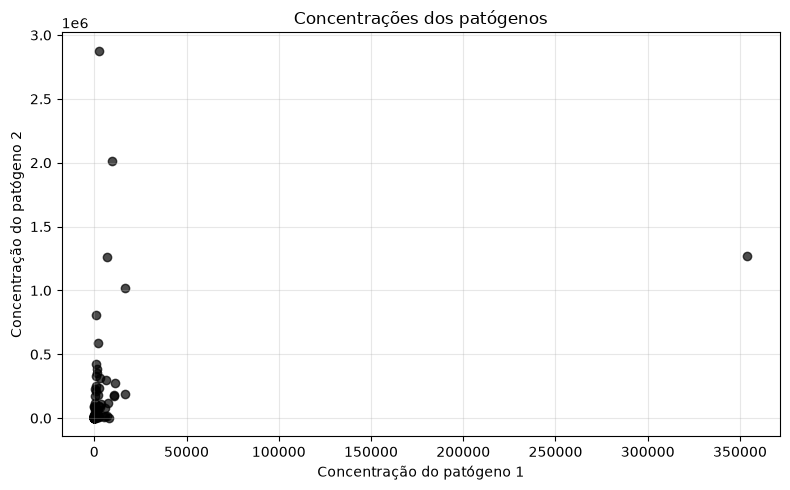

In [5]:
fig, ax = plt.subplots(figsize=(8, 5))

ax.scatter(x, y, color="black", alpha=0.7)

ax.set(
    title="Concentrações dos patógenos",
    xlabel="Concentração do patógeno 1",
    ylabel="Concentração do patógeno 2"
)

ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [8]:
def analisar_regressao(x, y, titulo):
    X = sm.add_constant(x)
    resultado = sm.OLS(y, X).fit()

    print(resultado.summary())

    grade = np.linspace(x.min(), x.max(), 200)
    X_grade = sm.add_constant(grade)

    previsoes = resultado.get_prediction(
        X_grade
    ).summary_frame(alpha=0.05)

    residuos = resultado.resid

    fig, axes = plt.subplots(2, 2, figsize=(12, 9))

    # Dados, reta e intervalos
    ax = axes[0, 0]

    ax.scatter(x, y, color="black", zorder=3)

    ax.fill_between(
        grade,
        previsoes["obs_ci_lower"].to_numpy(),
        previsoes["obs_ci_upper"].to_numpy(),
        color="gray",
        alpha=0.25,
        label="Predição de 95%"
    )

    ax.fill_between(
        grade,
        previsoes["mean_ci_lower"].to_numpy(),
        previsoes["mean_ci_upper"].to_numpy(),
        color="royalblue",
        alpha=0.25,
        label="Confiança de 95%"
    )

    ax.plot(
        grade,
        previsoes["mean"].to_numpy(),
        color="blue",
        label="Reta estimada"
    )

    ax.set(
        title="Ajuste da regressão",
        xlabel=x.name,
        ylabel=y.name
    )
    ax.legend()

    # Resíduos versus preditos
    ax = axes[0, 1]

    ax.scatter(resultado.fittedvalues, residuos, color="black")
    ax.axhline(0, color="red", linestyle="--")

    ax.set(
        title="Resíduos versus preditos",
        xlabel=f"Valores preditos de {y.name}",
        ylabel="Resíduo"
    )

    # Histograma e normal de referência
    ax = axes[1, 0]

    ax.hist(
        residuos,
        bins="auto",
        density=True,
        color="steelblue",
        edgecolor="white",
        alpha=0.7
    )

    media = residuos.mean()
    desvio = residuos.std(ddof=1)

    pontos = np.linspace(
        min(residuos.min(), media - 3 * desvio),
        max(residuos.max(), media + 3 * desvio),
        200
    )

    ax.plot(
        pontos,
        norm.pdf(pontos, loc=media, scale=desvio),
        color="red",
        label="Normal de referência"
    )

    ax.set(
        title="Histograma dos resíduos",
        xlabel="Resíduo",
        ylabel="Densidade"
    )
    ax.legend()

    # QQ-plot
    sm.qqplot(residuos, line="s", ax=axes[1, 1])
    axes[1, 1].set_title("QQ-plot dos resíduos")

    for ax in axes.flat:
        ax.grid(alpha=0.2)

    fig.suptitle(titulo)
    plt.tight_layout()
    plt.show()

    return resultado

                            OLS Regression Results                            
Dep. Variable:                CPatog2   R-squared:                       0.095
Model:                            OLS   Adj. R-squared:                  0.086
Method:                 Least Squares   F-statistic:                     10.81
Date:                Tue, 13 Oct 2026   Prob (F-statistic):            0.00138
Time:                        22:10:24   Log-Likelihood:                -1497.3
No. Observations:                 105   AIC:                             2999.
Df Residuals:                     103   BIC:                             3004.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       1.315e+05   3.76e+04      3.497      0.0

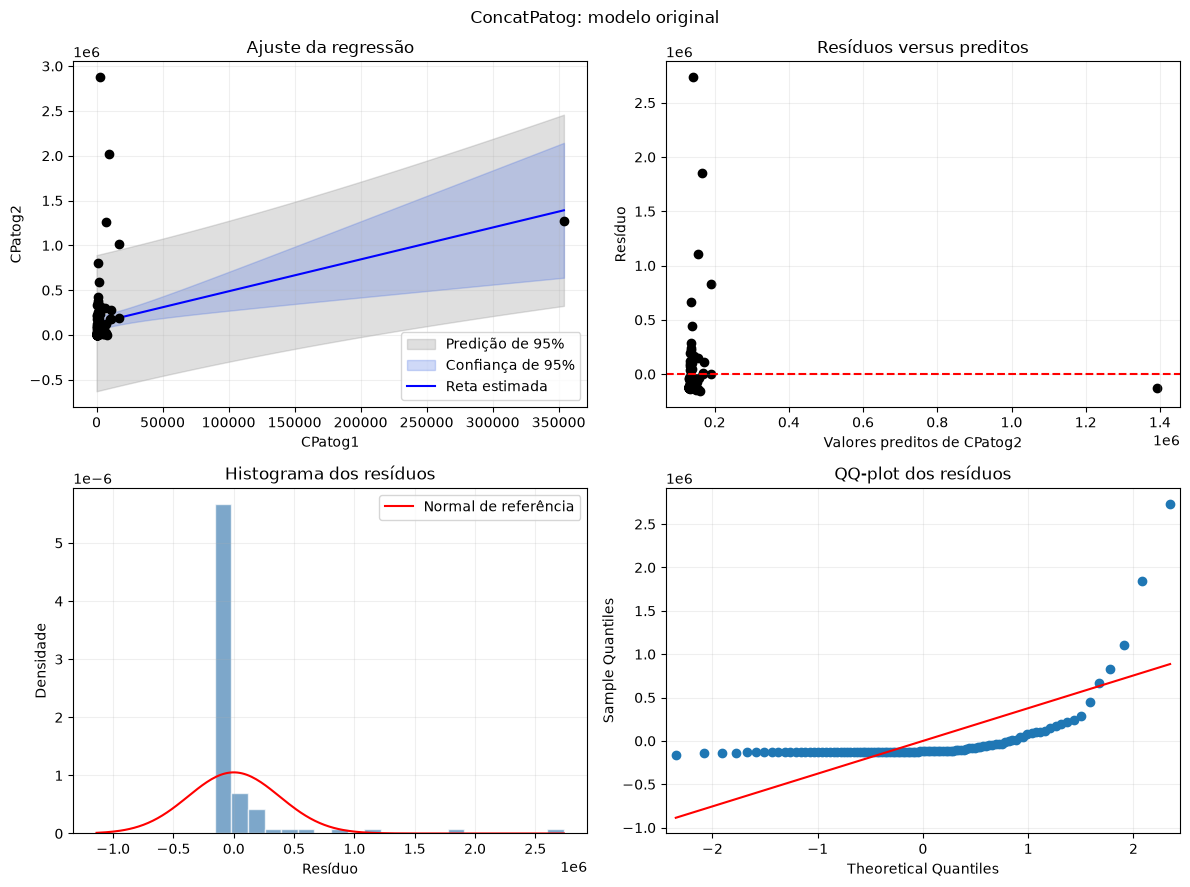

In [16]:
resultado_original = analisar_regressao(
    x,
    y,
    "ConcatPatog: modelo original"
)

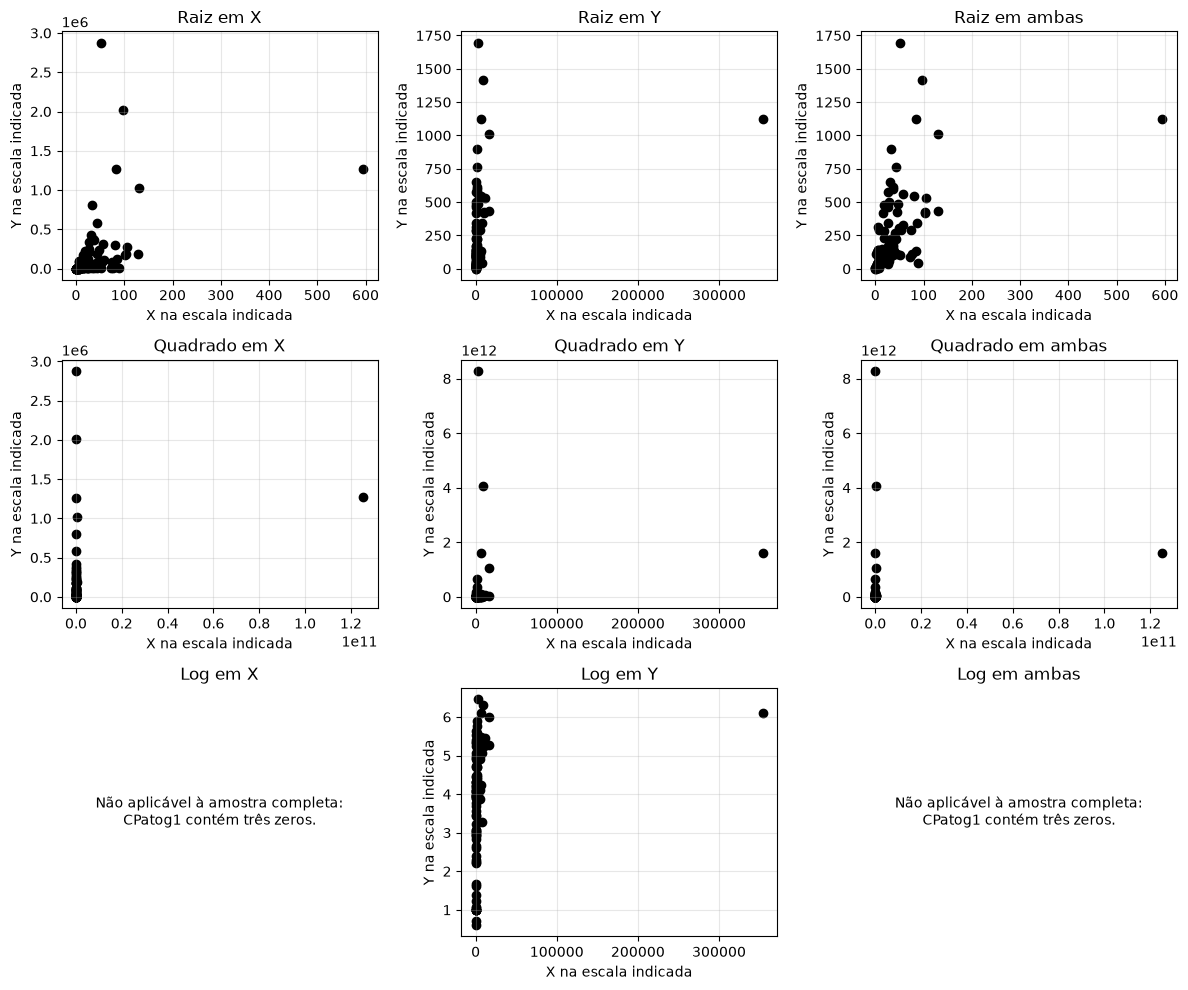

In [11]:
transformacoes = [
    ("Raiz em X", np.sqrt(x), y),
    ("Raiz em Y", x, np.sqrt(y)),
    ("Raiz em ambas", np.sqrt(x), np.sqrt(y)),

    ("Quadrado em X", x**2, y),
    ("Quadrado em Y", x, y**2),
    ("Quadrado em ambas", x**2, y**2),

    ("Log em X", None, None),
    ("Log em Y", x, np.log10(y)),
    ("Log em ambas", None, None)
]

fig, axes = plt.subplots(3, 3, figsize=(12, 10))

for ax, (nome, x_transformado, y_transformado) in zip(
    axes.flat, transformacoes
):
    ax.set_title(nome)

    if x_transformado is None:
        ax.text(
            0.5,
            0.5,
            "Não aplicável à amostra completa:\n"
            "CPatog1 contém três zeros.",
            ha="center",
            va="center",
            transform=ax.transAxes
        )
        ax.set_axis_off()
        continue

    ax.scatter(x_transformado, y_transformado, color="black")
    ax.set_xlabel("X na escala indicada")
    ax.set_ylabel("Y na escala indicada")
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

                            OLS Regression Results                            
Dep. Variable:          sqrt(CPatog2)   R-squared:                       0.263
Model:                            OLS   Adj. R-squared:                  0.256
Method:                 Least Squares   F-statistic:                     36.79
Date:                Tue, 13 Oct 2026   Prob (F-statistic):           2.20e-08
Time:                        22:07:23   Log-Likelihood:                -733.83
No. Observations:                 105   AIC:                             1472.
Df Residuals:                     103   BIC:                             1477.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
const           150.4407     29.568      5.088

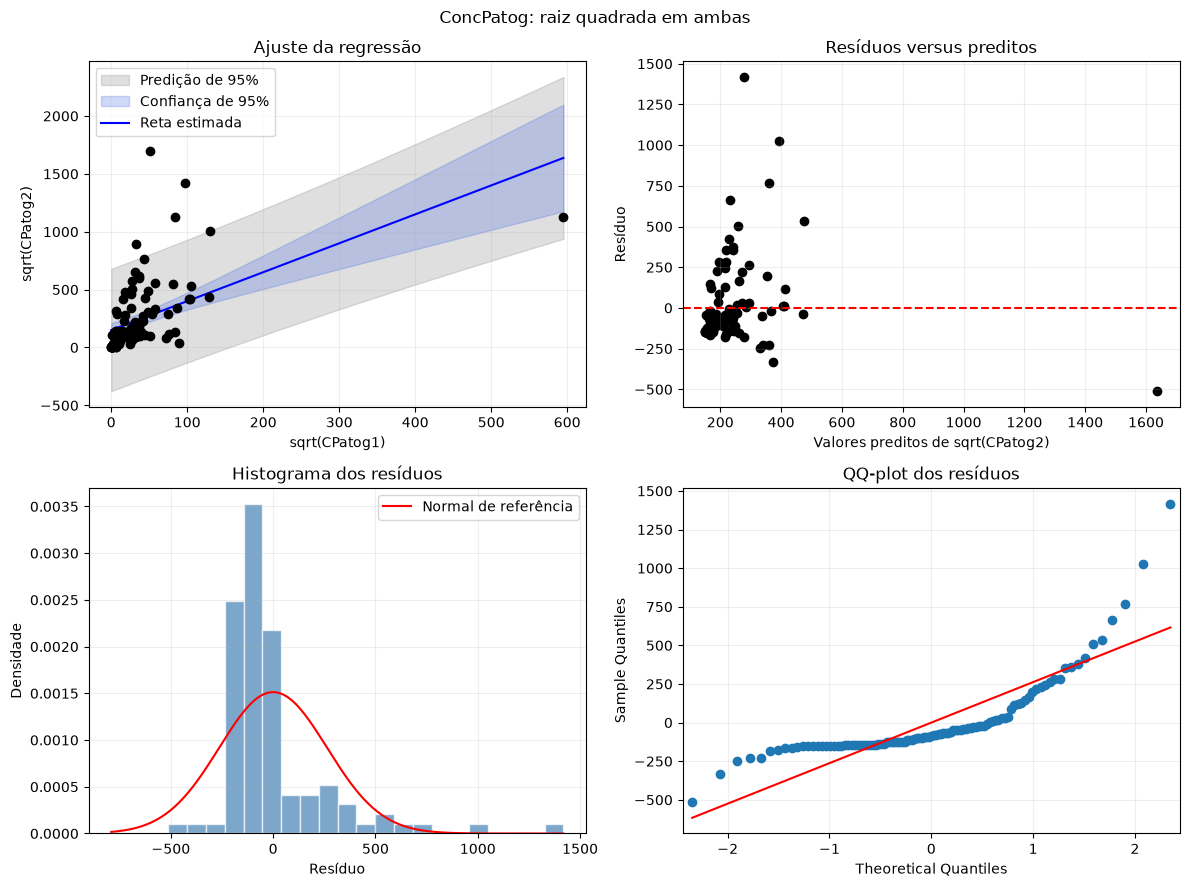

In [12]:
x_raiz = np.sqrt(x).rename("sqrt(CPatog1)")
y_raiz = np.sqrt(y).rename("sqrt(CPatog2)")

resultado_raiz = analisar_regressao(
    x_raiz,
    y_raiz,
    "ConcPatog: raiz quadrada em ambas"
)

                            OLS Regression Results                            
Dep. Variable:         log10(CPatog2)   R-squared:                       0.035
Model:                            OLS   Adj. R-squared:                  0.026
Method:                 Least Squares   F-statistic:                     3.771
Date:                Tue, 13 Oct 2026   Prob (F-statistic):             0.0549
Time:                        22:07:29   Log-Likelihood:                -186.09
No. Observations:                 105   AIC:                             376.2
Df Residuals:                     103   BIC:                             381.5
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          3.8888      0.142     27.412      0.0

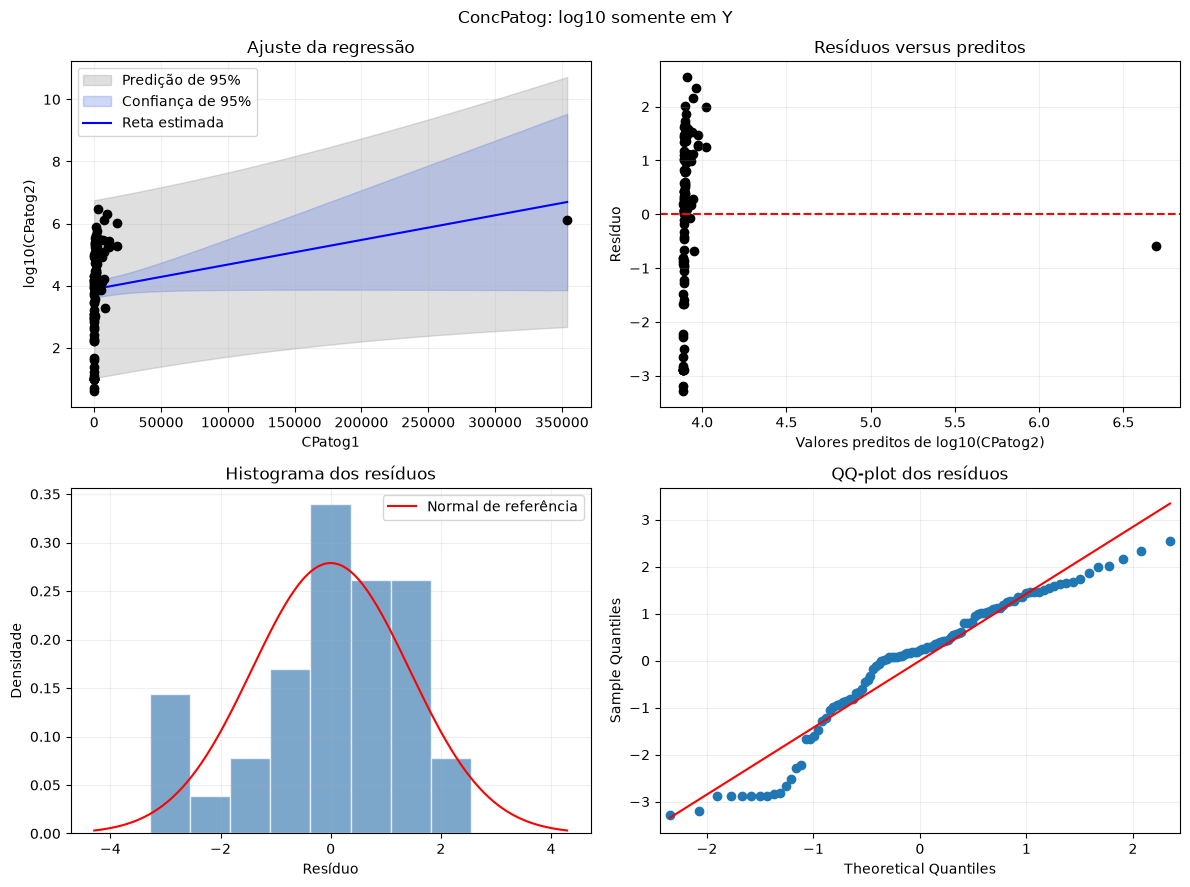

In [13]:
y_log = np.log10(y).rename("log10(CPatog2)")

resultado_log_y = analisar_regressao(
    x,
    y_log,
    "ConcPatog: log10 somente em Y"
)

                            OLS Regression Results                            
Dep. Variable:          sqrt(CPatog2)   R-squared:                       0.263
Model:                            OLS   Adj. R-squared:                  0.256
Method:                 Least Squares   F-statistic:                     36.79
Date:                Tue, 13 Oct 2026   Prob (F-statistic):           2.20e-08
Time:                        22:09:02   Log-Likelihood:                -733.83
No. Observations:                 105   AIC:                             1472.
Df Residuals:                     103   BIC:                             1477.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
const           150.4407     29.568      5.088

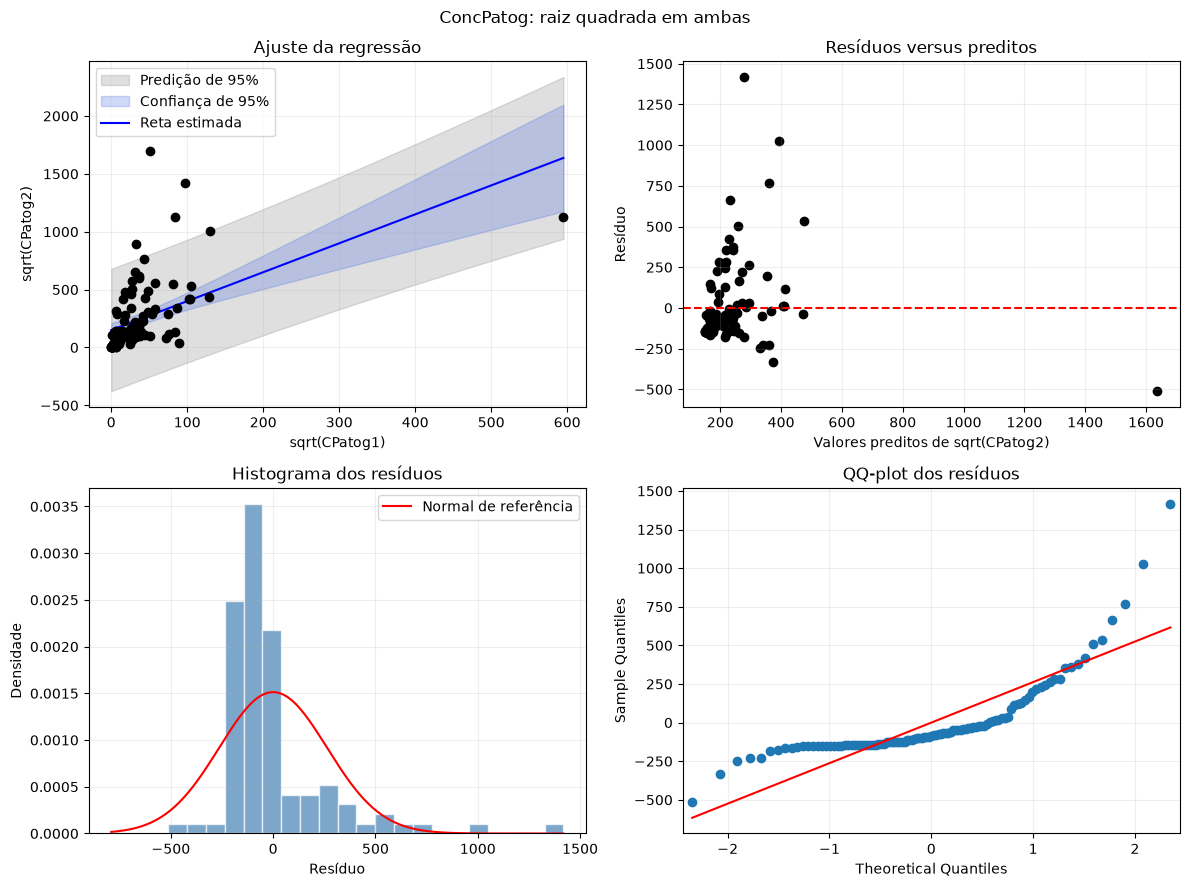

In [14]:
x_raiz = np.sqrt(x).rename("sqrt(CPatog1)")
y_raiz = np.sqrt(y).rename("sqrt(CPatog2)")

resultado_raiz = analisar_regressao(
    x_raiz,
    y_raiz,
    "ConcPatog: raiz quadrada em ambas"
)